# 2.5D DC compared with 3D and with the analytic vertical dyke

A dipole-dipole profile (a = 1 m, n = 2) crosses a 10 m wide vertical dyke: 100 Ω·m on the left, 1000 Ω·m
in the dyke ($0 < x < 10$ m) and 50 Ω·m on the right. The voltages computed with `GridDC` on a 3D grid and on a
2.5D grid are compared with the analytic solution (Van Nostrand & Cook, USGS Professional Paper 499) and, if
SimPEG is installed, with its 2D simulations.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('..'))   # notebook run from the examples directory

from pymmr.finite_volume import calc_padding, has_mumps
from pymmr.dc import GridDC, VerticalDyke

solver = 'mumps' if has_mumps else 'superlu'
print('solver:', solver)

try:
    import simpeg
    has_simpeg = True
except ImportError:
    has_simpeg = False
print('SimPEG available:', has_simpeg)

solver: mumps
SimPEG available: False


## Model, survey and analytic solution

Electrodes C1, C2, P1, P2 at $x$, $x+1$, $x+2$ and $x+3$ m, on the surface along $y = 0$; the dyke strikes along $y$.

In [2]:
rho1, rho2, rho3 = 100.0, 1000.0, 50.0
dyke = VerticalDyke(rho1, rho2, rho3, 10.0)

x = np.arange(-20.0, 27.0, 2.0).reshape(-1, 1)
zero = np.zeros(x.shape)
c1c2 = np.c_[x, zero, zero, 1.0 + x, zero, zero]
p1p2 = np.c_[2.0 + x, zero, zero, 3.0 + x, zero, zero]
x_mid = c1c2[:, 0] + 1.5       # centre of the array

va = dyke.fwd_mod(c1c2, p1p2)    # V, for a current of 1 A

## 3D finite volumes

1 m cells around the profile, with padding cells on the sides and at depth.

In [3]:
x = np.arange(-30.0, 40.01)
y = np.arange(-5.0, 5.01)
z = np.arange(-30.0, 0.01)

pad = np.cumsum(calc_padding(1.0, 25))

x = np.r_[x[0] - pad[::-1], x, x[-1] + pad]
y = np.r_[y[0] - pad[::-1], y, y[-1] + pad]
z = np.r_[z[0] - pad[::-1], z]

g = GridDC((x, y, z))
g.set_solver(solver)
g.set_survey_ert(c1c2, p1p2, cs=1.0)

sigma = 1.0 / rho1 + np.zeros((g.fv.nx, g.fv.ny, g.fv.nz))
sigma[g.fv.xc > 0.0, :, :] = 1.0 / rho2
sigma[g.fv.xc > 10.0, :, :] = 1.0 / rho3
sigma = sigma.flatten(order='F')

v3 = 0.001 * g.fwd_mod(sigma)    # mV -> V

## 2.5D finite volumes

The same grid in the $(x, z)$ plane; the conductivity is invariant along $y$. The inverse Fourier transform
uses 11 wavenumbers optimized for the grid (`optimize_k_g`), and `apply_bc` corrects the error of the transform
with the analytic primary field.

In [4]:
g2 = GridDC((x, z))
g2.set_solver(solver)
g2.set_survey_ert(c1c2, p1p2, cs=1.0)
g2.fv.optimize_k_g(11)
g2.apply_bc = True

sigma2 = 1.0 / rho1 + np.zeros((g2.fv.nx, g2.fv.nz))
sigma2[g2.fv.xc > 0.0, :] = 1.0 / rho2
sigma2[g2.fv.xc > 10.0, :] = 1.0 / rho3
sigma2 = sigma2.flatten(order='F')

v25 = 0.001 * g2.fwd_mod(sigma2)    # mV -> V

## SimPEG 2D (optional)

Nodal and cell-centred 2D simulations of SimPEG on the same $(x, z)$ grid, with SimPEG's default solver.
This cell is skipped if SimPEG is not installed.

In [5]:
simpeg_data = {}
if has_simpeg:
    import simpeg.maps
    from discretize import TensorMesh
    from simpeg.electromagnetics.static import resistivity as dc
    from simpeg.electromagnetics.static.utils.static_utils import generate_dcip_sources_line

    # dipole-dipole line with the same electrodes (every other source, as in the pymmr survey)
    source_list = generate_dcip_sources_line(
        survey_type="dipole-dipole", data_type="volt", dimension_type="2D",
        end_points=np.r_[c1c2[0, 0], c1c2[-1, 0] + 4], topo=np.c_[x, np.zeros(x.shape)],
        num_rx_per_src=1, station_spacing=1.0)
    survey = dc.survey.Survey(source_list[::2])
    x_simpeg = survey.locations_a[:, 0] + 1.5

    mesh = TensorMesh((np.diff(x), np.diff(z)), origin=(x[0], z[0]))
    sig = 1.0 / rho1 + np.zeros((g2.fv.nz, g2.fv.nx))     # x is the fast axis in discretize
    sig[:, g2.fv.xc > 0.0] = 1.0 / rho2
    sig[:, g2.fv.xc > 10.0] = 1.0 / rho3
    sig = sig.flatten()
    conductivity_map = simpeg.maps.IdentityMap(mesh)

    for name, Simulation in (('nodal', dc.simulation_2d.Simulation2DNodal),
                             ('cell-centred', dc.simulation_2d.Simulation2DCellCentered)):
        simulation = Simulation(mesh, survey=survey, sigmaMap=conductivity_map)
        simpeg_data[name] = simulation.dpred(sig)    # V

## Comparison

Voltages along the profile (top) and relative difference with the analytic solution (bottom).

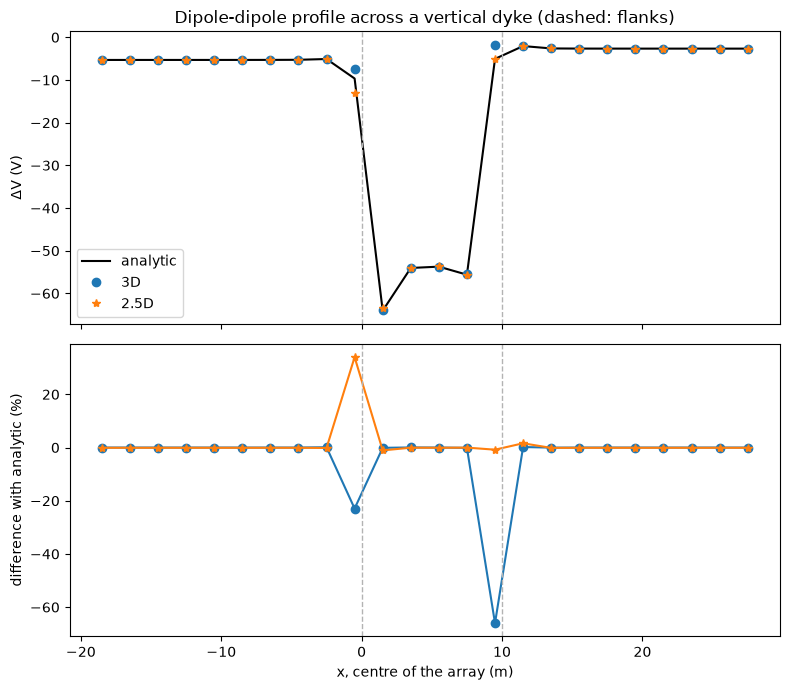

3D                       max |difference| = 66.04 %
2.5D                     max |difference| = 33.98 %


In [6]:
results = {'3D': (x_mid, v3, 'o'), '2.5D': (x_mid, v25, '*')}
for name, d in simpeg_data.items():
    results['SimPEG 2D ' + name] = (x_simpeg, d, '+')

fig, ax = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
ax[0].plot(x_mid, va, 'k-', label='analytic')
for name, (xm, v, marker) in results.items():
    ax[0].plot(xm, v, marker, label=name)
    ax[1].plot(xm, 100 * (v - va) / va, marker + '-', label=name)
for xd in (0.0, 10.0):
    for a in ax:
        a.axvline(xd, color='0.7', ls='--', lw=1)
ax[0].set_ylabel('ΔV (V)')
ax[0].legend()
ax[0].set_title('Dipole-dipole profile across a vertical dyke (dashed: flanks)')
ax[1].set_ylabel('difference with analytic (%)')
ax[1].set_xlabel('x, centre of the array (m)')
fig.tight_layout()
plt.show()

for name, (xm, v, _) in results.items():
    print(f'{name:24s} max |difference| = {100 * np.max(np.abs((v - va) / va)):.2f} %')